# Tổng hợp phát hiện — Suy luận nhân quả ở đuôi phân phối bằng EASE (5 cổ phiếu HOSE)

Notebook này gom **những phát hiện quan trọng nhất** của bước xử lý từ `01_ease_simulation.ipynb` (kiểm chứng bằng mô phỏng) và
`02_ease_real_data.ipynb` (dữ liệu thật). Mỗi phát hiện gồm: **(1)** giải thích — tính gì, công thức, các bước; **(2)** code; **(3)** hình;
**(4)** phân tích ngắn. Phương pháp: **EASE** — Gnecco, Meinshausen, Peters & Engelke (2021), *Causal discovery in heavy-tailed models*,
Ann. Statist. 49(3), 1755–1778.

| # | Phát hiện | Hệ quả |
|---|---|---|
| 1 | Cài đặt EASE đúng; trong mô phỏng EASE tốt hơn Rank PC và ngẫu nhiên, kém Pairwise LiNGAM khi đuôi nhẹ | Dùng EASE kèm baseline LiNGAM để đối chiếu |
| 2 | Biên độ ±7% **không** làm lệch EASE; nhân tố ẩn mới gây hại | EASE dùng được trên dữ liệu HOSE, khác Hill |
| 3 | Sau lọc GARCH, đuôi gần dạng mũ (ξ̂ ≈ 0), lợi suất thô bị chặn (ξ̂ < −0,9) | Giả định đuôi dày chỉ thoả một phần → kết luận mang tính gợi ý |
| 4 | Mọi cặp có $\hat\Psi_{jk},\hat\Psi_{kj} \in (0{,}55;0{,}79)$ | Mẫu hình **nguyên nhân chung**, không nhân quả trực tiếp |
| 5 | Thứ tự EASE: NVL → VHM → VPB → HPG → STB; NVL là gốc ở 73% bootstrap | Cú sốc bất động sản mang tính riêng; ngân hàng/thép chịu chung sốc |
| 6 | Cú sập lan mạnh hơn cú tăng ($\bar\Gamma^-$ 0,82 so với $\bar\Gamma$ 0,66) | Mô hình rủi ro cần tách đuôi dưới |
| 7 | Baseline đồng thuận với EASE (0,8–0,9); Rank PC không định hướng được | Cấu trúc tồn tại cả ở thân lẫn đuôi phân phối |

**Ký hiệu chung.** $r_{i,t}$: lợi suất log ngày của mã $i$; $z_{i,t}$: phần dư chuẩn hoá GARCH(1,1)-t; $F_j$: hàm phân phối của biến $j$;
$k = \lfloor n^{0,4}\rfloor$: số quan sát cực trị dùng ở mỗi đuôi ($n = 2120$ → $k = 21$).

**Chạy trước:** `01_ease_simulation.ipynb` và `02_ease_real_data.ipynb` (tạo các bảng trong `report/table/processing/` và
`data/processed/garch_std_resid.parquet`). Hình được lưu vào `report/figure/processing/finding_*.png|pdf`.

## 0. Thiết lập

Nạp module dùng chung, đọc phần dư GARCH $z$ (đã lưu ở notebook 02) và lợi suất thô $r$; định nghĩa hàm đọc bảng kết quả.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as U
import causal_tail as CT
import causal_baselines as CB
import tail_preprocessing as TP

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.3f}".format)
SYMBOLS, COL, PAL = U.SYMBOLS, U.SYMBOL_COLORS, U.PALETTE
FOLDER = "processing"                      # hình → report/figure/processing, bảng → report/table/processing
METHOD_COLORS = {"EASE": PAL["blue_main"], "Pairwise LiNGAM": PAL["red_strong"], "ICA-LiNGAM": PAL["green_3"],
                 "Rank PC": PAL["violet"], "Ngẫu nhiên": PAL["neutral"]}

TAB = ROOT / "report" / "table" / FOLDER
def read(name, **kw):
    path = TAB / f"{name}.csv"
    if not path.exists():
        raise FileNotFoundError(f"Thiếu {path.name} — chạy notebook 01 và 02 trước.")
    return pd.read_csv(path, encoding="utf-8-sig", **kw)

con = U.connect()
r = con.execute("SELECT * FROM v_returns_wide").df().set_index("time")[SYMBOLS].dropna()
z = pd.read_parquet(ROOT / "data" / "processed" / "garch_std_resid.parquet")[SYMBOLS]
n, K = len(z), CT.default_k(len(z))
print(f"z: n = {n} phiên, k = {K}")

z: n = 2120 phiên, k = 21


## Phát hiện 1 — Cài đặt đúng; EASE vượt Rank PC và ngẫu nhiên, nhưng kém Pairwise LiNGAM khi đuôi không quá dày

**Tính gì:** SID chuẩn hoá trung bình (20 lần lặp mỗi cấu hình) của 5 phương pháp trên dữ liệu mô phỏng từ SCM tuyến tính với nhiễu
Student-t bậc $\alpha$, kịch bản gần thị trường nhất (`hidden_censored`: 2 nhân tố ẩn + chặn 1,5% mỗi đuôi), $n = 2000$.

**Công thức (SID).** Thứ tự $\hat\pi$ → DAG đầy đủ $\hat G$; với mỗi cặp $(x, y)$, $\hat G$ suy ra $p(y\mid do(x))$ bằng cách hiệu chỉnh theo
$\mathrm{pa}_{\hat G}(x)$:
$$\mathrm{SID} = \frac{1}{p(p-1)}\#\{(x,y): \mathrm{pa}_{\hat G}(x) \text{ không là tập hiệu chỉnh hợp lệ cho } (x,y) \text{ trong } G\} \in [0,1].$$
0 = mọi tác động can thiệp suy ra đúng. Kiểm tra quần thể (Lemma 1, Ví dụ 1, Mệnh đề 1) và 37 test đơn vị đã xác nhận cài đặt.

**Các bước:** đọc `01_simulation_results.csv`; lọc kịch bản và $n$; vẽ SID trung bình ± sai số chuẩn theo $\alpha$ và $p$.

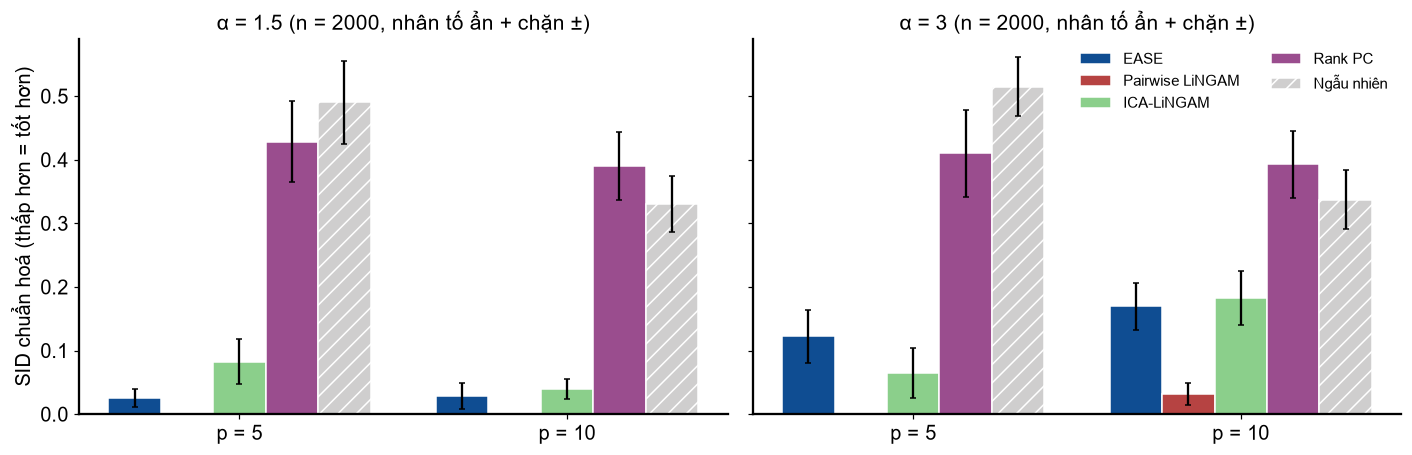

method    EASE  Pairwise LiNGAM  ICA-LiNGAM  Rank PC  Ngẫu nhiên
alpha p                                                         
1.500 5  0.025            0.000       0.083    0.428       0.490
      10 0.029            0.000       0.040    0.390       0.330
3.000 5  0.123            0.000       0.065    0.410       0.515
      10 0.169            0.032       0.183    0.393       0.337

In [2]:
sim = read("01_simulation_results")
d = sim[(sim.setting == "hidden_censored") & (sim.n == 2000)]
g = d.groupby(["alpha", "p", "method"])["SID"].agg(["mean", "sem"]).reset_index()
methods = list(CB.METHODS)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.3), sharey=True)
w = 0.16
for ax, a in zip(axes, (1.5, 3.0)):
    for i, m in enumerate(methods):
        gg = g[(g.alpha == a) & (g.method == m)].set_index("p").reindex([5, 10])
        x = np.arange(2) + (i - 2) * w
        ax.bar(x, gg["mean"], w, yerr=gg["sem"], color=METHOD_COLORS[m], edgecolor="white", capsize=2, label=m,
               hatch="//" if m == "Ngẫu nhiên" else None)
    ax.set_xticks(range(2), ["p = 5", "p = 10"]); ax.set_title(f"α = {a:g} (n = 2000, nhân tố ẩn + chặn ±)")
axes[0].set_ylabel("SID chuẩn hoá (thấp hơn = tốt hơn)")
axes[1].legend(fontsize=10, loc="upper right", ncol=2)
U.finalize_figure(fig, "finding_1_simulation", folder=FOLDER); plt.show()
g.pivot_table(index=["alpha", "p"], columns="method", values="mean")[methods]

### Phân tích

- Ở đuôi rất dày ($\alpha = 1{,}5$), EASE đạt SID 0,03 — tốt hơn ICA-LiNGAM (0,04–0,08), chỉ sau Pairwise LiNGAM (≈ 0); ở $\alpha = 3$ (gần lợi suất
  cổ phiếu) EASE còn 0,12–0,17: kém Pairwise LiNGAM (0,00–0,03), ngang ICA-LiNGAM (0,07–0,18), nhưng vẫn **tốt hơn hẳn Rank PC và ngẫu nhiên** (0,34–0,52).
- Thứ hạng này trùng với mục 5.1 của bài báo. Pairwise LiNGAM được lợi vì dữ liệu mô phỏng tuyến tính trên **toàn** phân phối; EASE chỉ
  dùng $2k$ điểm cực trị và không cần giả định đó.
- Hệ quả: trên dữ liệu thật không có đáp án, nên đối chiếu EASE với LiNGAM (phát hiện 7) thay vì tin riêng một phương pháp.

## Phát hiện 2 — Biên độ ±7% không làm lệch EASE; nhân tố ẩn mới là nguồn sai số chính

**Tính gì:** mức thay đổi SID trung bình khi thêm từng yếu tố vào SCM tuyến tính, giữ nguyên $(n, p, \alpha)$:
$$\Delta_{\text{chặn}} = \overline{\mathrm{SID}}_{\texttt{censored}} - \overline{\mathrm{SID}}_{\texttt{linear}},\qquad
\Delta_{\text{ẩn}} = \overline{\mathrm{SID}}_{\texttt{hidden}} - \overline{\mathrm{SID}}_{\texttt{linear}}.$$

**Ý tưởng:** EASE chỉ cần biết **phiên nào** là cực trị của nguyên nhân và **hạng** của hệ quả trong các phiên đó:
$$\hat\Gamma_{jk} = \frac1k\sum_{i=1}^n \hat F_k(X_{ik})\,\mathbb 1\{X_{ij} > X_{(n-k),j}\}.$$
Phép chặn ±7% giữ nguyên hạng và giữ các phiên cực trị ở nhóm trên cùng (chỉ làm chúng trùng giá trị — được phá thế trùng ngẫu nhiên),
nên về nguyên tắc không làm lệch $\hat\Gamma$. Ước lượng Hill thì cần **độ lớn** cực trị, nên hỏng (EDA, phát hiện 4).

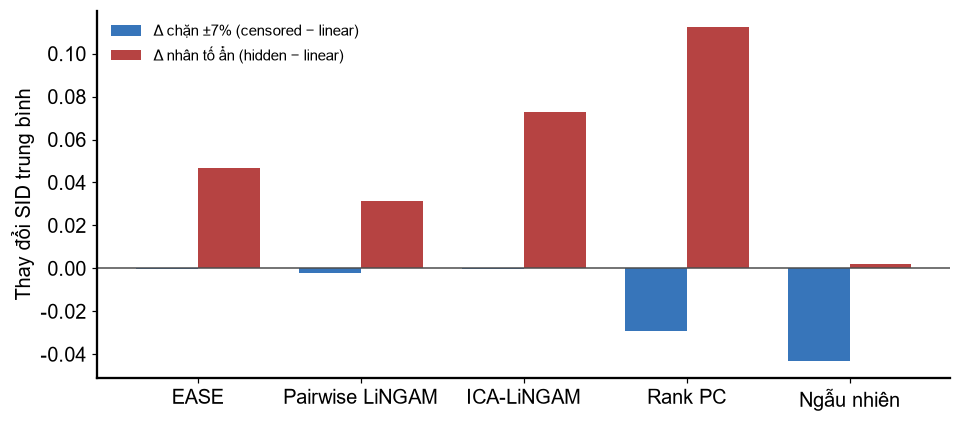

,Δ kiểm duyệt,Δ nhân tố ẩn,Δ cả hai
method,,,
EASE,-0.000,0.047,0.047
Pairwise LiNGAM,-0.002,0.031,0.016
ICA-LiNGAM,-0.000,0.073,0.095
Rank PC,-0.029,0.112,0.105
Ngẫu nhiên,-0.043,0.002,0.025


In [3]:
eff = read("01_effect_censoring_hidden", index_col=0).loc[methods]
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(methods)); w = 0.38
ax.bar(x - w / 2, eff["Δ kiểm duyệt"], w, color=PAL["blue_secondary"], label="Δ chặn ±7% (censored − linear)")
ax.bar(x + w / 2, eff["Δ nhân tố ẩn"], w, color=PAL["red_strong"], label="Δ nhân tố ẩn (hidden − linear)")
ax.axhline(0, color=PAL["gray_dark"], lw=1)
ax.set_xticks(x, methods); ax.set_ylabel("Thay đổi SID trung bình")
ax.legend(fontsize=10, loc="upper left")
U.finalize_figure(fig, "finding_2_censoring_vs_hidden", folder=FOLDER); plt.show()
eff

### Phân tích

- Chặn hai đuôi (1,5% mỗi đuôi, như tỷ lệ phiên trần/sàn thực tế 0,8–2,5%) **không làm thay đổi** SID của EASE (Δ ≈ 0,000) và của hai LiNGAM.
  Ở $n = 2000$, $k = 21$ < 30 phiên bị chặn: mọi điểm cực trị EASE dùng đều là phiên "trần", vậy mà kết quả không đổi — đúng như lập luận ở trên.
- Nhân tố ẩn làm mọi phương pháp xấu đi (EASE +0,05; ICA-LiNGAM +0,07; Rank PC +0,11). Đây là rủi ro thật của dữ liệu cổ phiếu,
  nơi nhân tố thị trường (VN-Index) không nằm trong dữ liệu.
- Vì vậy phân tích dữ liệu thật **có thể dùng trực tiếp** lợi suất bị chặn; điều cần thận trọng là diễn giải khi có nhân tố chung.

## Phát hiện 3 — Giả định đuôi dày chỉ thoả một phần

**Tính gì:** tham số hình dạng GPD $\hat\xi$ của phần vượt ngưỡng phân vị 95%, đuôi trên và dưới, trên lợi suất thô $r$ và phần dư
GARCH $z$ (bảng `02_gpd_shape.csv`).

**Công thức.** $P(X - u \le y \mid X > u) = 1 - (1 + \xi y/\beta)^{-1/\xi}$. $\xi > 0$: đuôi dày Pareto với chỉ số $\alpha = 1/\xi$ (điều EASE cần);
$\xi = 0$: đuôi mũ; $\xi < 0$: đuôi bị chặn. $\widehat{\mathrm{SE}} \approx (1+\hat\xi)/\sqrt{n_u}$, chỉ hợp lệ khi $\hat\xi > -0{,}5$.

**Vì sao cần lọc GARCH:** EDA (phát hiện 5) cho thấy biến động cụm; $z_t = (r_t - \hat\mu)/\hat\sigma_t$ loại hiệu ứng ARCH
(Ljung–Box của $z^2$: p = 0,29–0,81 so với p ≈ 0 của $r^2$) để các phiên cực trị gần độc lập như Định lý 2 yêu cầu.

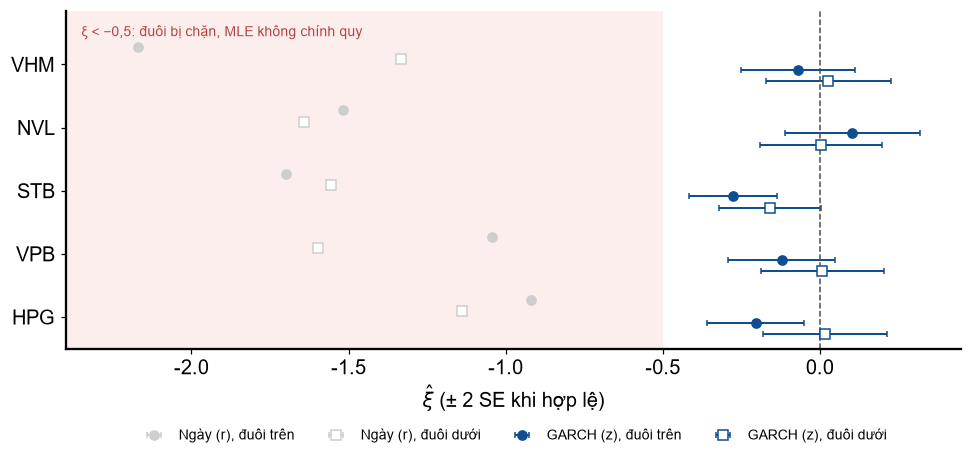

bien_the GARCH (z)        Ngày (r)       
duoi          dưới   trên     dưới   trên
ma                                       
VHM          0.027 -0.069   -1.332 -2.169
NVL          0.004  0.103   -1.640 -1.518
STB         -0.158 -0.277   -1.555 -1.698
VPB          0.008 -0.121   -1.597 -1.042
HPG          0.017 -0.204   -1.140 -0.919

In [4]:
gpd = read("02_gpd_shape")
gpd = gpd[gpd.bien_the.isin(["Ngày (r)", "GARCH (z)"])]
fig, ax = plt.subplots(figsize=(9, 4.4))
offs = {("Ngày (r)", "trên"): -0.27, ("Ngày (r)", "dưới"): -0.09, ("GARCH (z)", "trên"): 0.09, ("GARCH (z)", "dưới"): 0.27}
mk = {"trên": "o", "dưới": "s"}
vc = {"Ngày (r)": PAL["neutral"], "GARCH (z)": PAL["blue_main"]}
for (v, t), off in offs.items():
    dd = gpd[(gpd.bien_the == v) & (gpd.duoi == t)].set_index("ma").loc[SYMBOLS]
    xerr = np.where(dd.se.isna(), 0, 2 * dd.se.fillna(0))
    ax.errorbar(dd.xi, np.arange(5) + off, xerr=xerr, fmt=mk[t], color=vc[v], mfc=vc[v] if t == "trên" else "white",
                ms=6, capsize=2, lw=1.3, label=f"{v}, đuôi {t}")
ax.axvline(0, color=PAL["gray_dark"], ls="--", lw=1)
ax.axvspan(-2.4, -0.5, color=PAL["red_1"], alpha=0.35, lw=0)
ax.text(-2.35, -0.62, "ξ < −0,5: đuôi bị chặn, MLE không chính quy", fontsize=9, color=PAL["red_strong"], va="top")
ax.set_yticks(range(5), SYMBOLS); ax.invert_yaxis(); ax.set_xlim(-2.4, 0.45)
ax.set_ylim(4.5, -0.85)
ax.set_xlabel(r"$\hat\xi$ (± 2 SE khi hợp lệ)")
ax.legend(fontsize=9, loc="upper center", ncol=4, bbox_to_anchor=(0.5, -0.2))
U.finalize_figure(fig, "finding_3_tail_shape", folder=FOLDER); plt.show()
gpd.pivot_table(index="ma", columns=["bien_the", "duoi"], values="xi").loc[SYMBOLS]

### Phân tích

- Lợi suất thô: $\hat\xi$ từ −0,9 đến −2,2 — dấu vết rõ của biên độ ±7%, **không** phải đuôi dày.
- Phần dư GARCH: $\hat\xi$ trong khoảng −0,28 … +0,10, phần lớn không khác 0; các mã có khoảng tin cậy chồng nhau (chỉ số đuôi **chung** —
  chấp nhận được) nhưng **không** có bằng chứng rõ cho $\xi > 0$. GARCH-t đã "hút" độ dày đuôi vào biến động có điều kiện.
- Kết quả EASE trên dữ liệu thật vì vậy mang tính **gợi ý** — giống tình huống Nestlé/Novartis trong mục 5.2 của bài báo.
  Mô phỏng (phát hiện 1) cho biết mức sai số kỳ vọng khi đuôi nhẹ hơn: EASE vẫn tốt hơn ngẫu nhiên rõ rệt.

## Phát hiện 4 — Mọi cặp mã rơi vào vùng "nguyên nhân chung"

**Tính gì:** với 10 cặp mã, vẽ điểm $(\hat\Psi_{jk}, \hat\Psi_{kj})$ trên $z$, $k = 21$, cùng khoảng bootstrap 90% của hiệu.

**Công thức.**
$$\hat\Psi_{jk} = \frac{1}{2k}\Big[\sum_{i\in\mathcal U_j}\sigma\big(\hat F_k(X_{ik})\big) + \sum_{i\in\mathcal L_j}\sigma\big(\hat F_k(X_{ik})\big)\Big],\quad \sigma(v) = |2v-1|,$$
$\mathcal U_j,\mathcal L_j$: $k$ phiên có $X_j$ lớn nhất/nhỏ nhất. **Đọc theo Bảng 2 của bài báo:** điểm ở cạnh trên/phải ($=1$) → nhân quả trực tiếp;
điểm ở góc $(1/2, 1/2)$ → không liên hệ; điểm **bên trong** hình vuông $(1/2,1)^2$ → nguyên nhân chung.

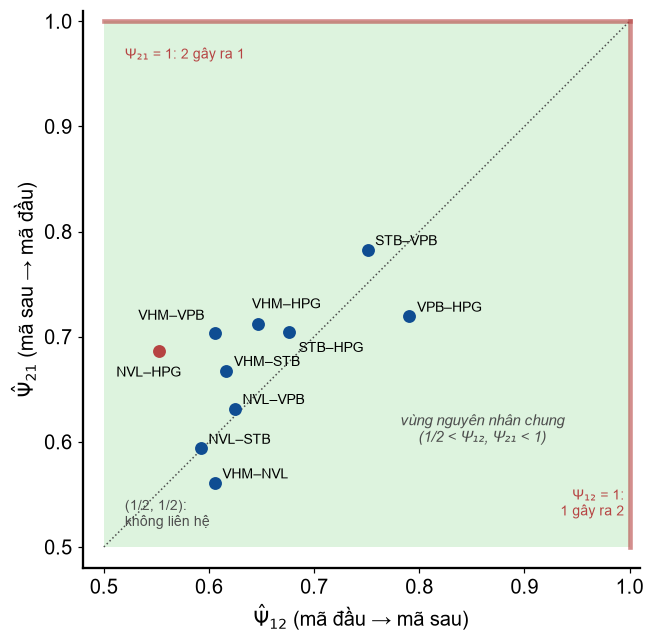

Ψ̂ ngoài đường chéo: min = 0.55, max = 0.79


,D,q05,q95,co_y_nghia_10pct
cap,,,,
VHM–NVL,0.045,-0.068,0.155,False
VHM–STB,-0.051,-0.136,0.059,False
VHM–VPB,-0.098,-0.164,0.030,False
VHM–HPG,-0.066,-0.154,0.045,False
NVL–STB,-0.002,-0.092,0.118,False
NVL–VPB,-0.007,-0.117,0.084,False
NVL–HPG,-0.134,-0.230,-0.039,True
STB–VPB,-0.032,-0.125,0.044,False
STB–HPG,-0.028,-0.138,0.062,False


In [5]:
Psi = CT.tail_coef_matrix(z, k=K, kind="psi")
asym = read("02_bootstrap_asymmetry", index_col=0)
LABEL_OFFSET = {"VHM–VPB": (-50, 9), "VHM–HPG": (-4, 10), "STB–HPG": (6, -13), "NVL–HPG": (-28, -17)}  # tránh chữ chồng
fig, ax = plt.subplots(figsize=(6.4, 6))
ax.add_patch(plt.Rectangle((0.5, 0.5), 0.5, 0.5, fill=True, color=PAL["green_1"], lw=0, zorder=0))
ax.plot([0.5, 1], [0.5, 1], color=PAL["gray_dark"], ls=":", lw=1)
for side in ([1, 1], [0.5, 1]), ([0.5, 1], [1, 1]):
    ax.plot(*side, color=PAL["red_strong"], lw=3, alpha=0.6)
ax.text(0.995, 0.53, "Ψ₁₂ = 1:\n1 gây ra 2", ha="right", fontsize=9, color=PAL["red_strong"])
ax.text(0.52, 0.975, "Ψ₂₁ = 1: 2 gây ra 1", fontsize=9, color=PAL["red_strong"], va="top")
ax.text(0.52, 0.52, "(1/2, 1/2):\nkhông liên hệ", fontsize=9, color=PAL["gray_dark"])
ax.text(0.86, 0.6, "vùng nguyên nhân chung\n(1/2 < Ψ₁₂, Ψ₂₁ < 1)", fontsize=10, color=PAL["gray_dark"], ha="center", style="italic")
for cap, row in asym.iterrows():
    a, b = cap.split("–")
    sig = row.co_y_nghia_10pct
    ax.scatter(Psi.loc[a, b], Psi.loc[b, a], s=55, color=PAL["red_strong"] if sig else PAL["blue_main"], zorder=3)
    ax.annotate(f"{a}–{b}", (Psi.loc[a, b], Psi.loc[b, a]), xytext=LABEL_OFFSET.get(cap, (5, 3)),
                textcoords="offset points", fontsize=9)
ax.set_xlim(0.48, 1.01); ax.set_ylim(0.48, 1.01); ax.set_aspect("equal")
ax.set_xlabel(r"$\hat\Psi_{12}$ (mã đầu → mã sau)"); ax.set_ylabel(r"$\hat\Psi_{21}$ (mã sau → mã đầu)")
U.finalize_figure(fig, "finding_4_common_cause", folder=FOLDER); plt.show()
off = ~np.eye(5, dtype=bool)
print(f"Ψ̂ ngoài đường chéo: min = {Psi.values[off].min():.2f}, max = {Psi.values[off].max():.2f}")
asym

### Phân tích

- Cả 10 cặp nằm **sâu trong** vùng nguyên nhân chung: $\hat\Psi$ từ 0,55 đến 0,79, không điểm nào chạm cạnh $=1$.
  Các điểm gần đường chéo — bất đối xứng nhỏ; chỉ cặp NVL–HPG (đỏ) có hiệu khác 0 ở mức 10%.
- Cụm cao nhất là VPB–STB và VPB–HPG (~0,7–0,8): cực trị của ngân hàng và thép xảy ra cùng nhau; các cặp có NVL thấp nhất (~0,55–0,69).
- Diễn giải: cú sốc cực trị giữa các mã chủ yếu do **nguồn chung** (thị trường, chính sách, dòng tiền) chứ không lan trực tiếp từ mã này
  sang mã kia — nhất quán với EDA (một nhân tố chung chiếm ưu thế, không có quan hệ Granger).

## Phát hiện 5 — Thứ tự EASE: bất động sản ở gốc, ngân hàng/thép ở sau; vững ở mức nhóm

**Tính gì:** thứ tự nhân quả EASE trên $\hat\Psi$ và độ ổn định của nó qua 500 mẫu bootstrap (bảng `02_bootstrap_rank_freq.csv`) và
qua $k = \lfloor n^\nu\rfloor$, $\nu \in [0{,}2;\,0{,}7]$ (bảng `02_order_by_k.csv`).

**EASE** (mục 3.1): lặp $s = 1,\dots,p$: với mỗi nút $i$ còn lại, $M_i^{(s)} = \max_{j\ne i}\hat\Psi_{ji}$; chọn $i_s = \arg\min_i M_i^{(s)}$
làm nút kế tiếp. Nút được chọn trước là nút **ít bị nút khác kéo theo** nhất ở đuôi. Thứ tự chỉ khẳng định "nút sau không là tổ tiên của nút trước".

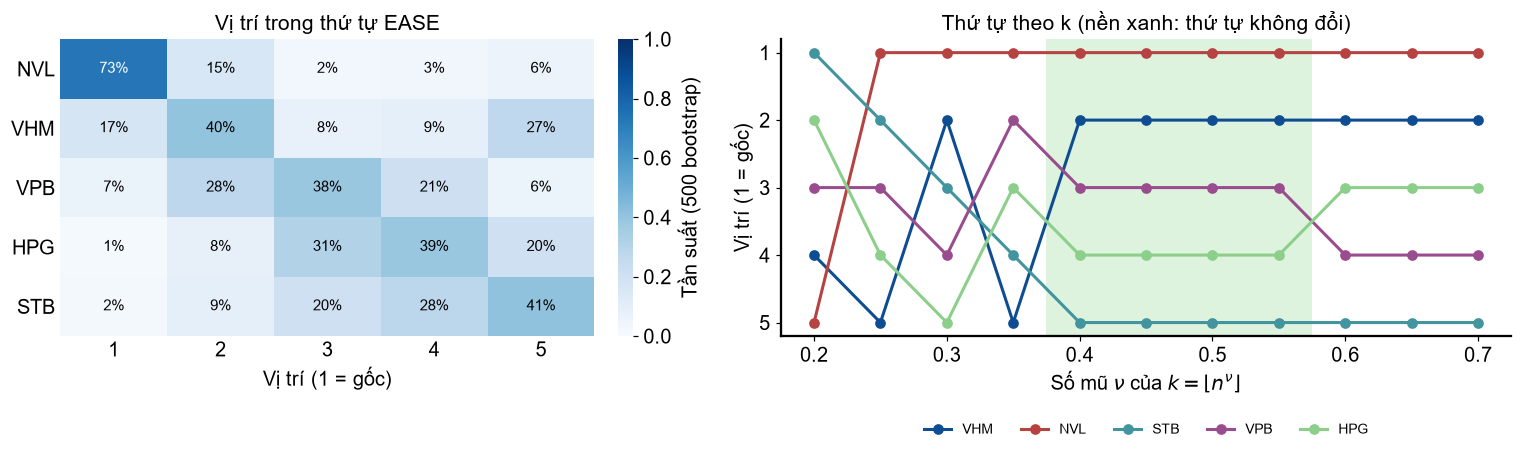

Thứ tự EASE (k = 21): NVL → VHM → VPB → HPG → STB


,chon,VHM,NVL,STB,VPB,HPG
buoc,,,,,,
1,NVL,0.712,0.687,0.783,0.751,0.791
2,VHM,0.712,NaN,0.783,0.751,0.791
3,VPB,NaN,NaN,0.783,0.751,0.791
4,HPG,NaN,NaN,0.704,NaN,0.677
5,STB,NaN,NaN,NaN,NaN,NaN


In [6]:
order_main = CT.ease(Psi)
rank_freq = read("02_bootstrap_rank_freq", index_col=0)
rank_freq.columns = rank_freq.columns.astype(int)
by_k = read("02_order_by_k", index_col=0)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), gridspec_kw={"width_ratios": [1, 1.25]})
U.make_heatmap(axes[0], rank_freq.loc[order_main], cmap="Blues", vmin=0, vmax=1, fmt="{:.0%}",
               cbar_label="Tần suất (500 bootstrap)", title="Vị trí trong thứ tự EASE")
axes[0].set_xlabel("Vị trí (1 = gốc)")
nus = [float(s.split("=")[1].split()[0]) for s in by_k.index]
for s in SYMBOLS:
    pos = [list(by_k.iloc[i]).index(s) + 1 for i in range(len(by_k))]
    axes[1].plot(nus, pos, "o-", color=COL[s], lw=2, ms=6, label=s)
axes[1].axvspan(0.375, 0.575, color=PAL["green_1"], lw=0, zorder=0)
axes[1].set_yticks(range(1, 6)); axes[1].invert_yaxis()
axes[1].set_xlabel(r"Số mũ $\nu$ của $k=\lfloor n^{\nu}\rfloor$"); axes[1].set_ylabel("Vị trí (1 = gốc)")
axes[1].set_title("Thứ tự theo k (nền xanh: thứ tự không đổi)"); axes[1].legend(ncol=5, fontsize=9, loc="lower center",
                                                                              bbox_to_anchor=(0.5, -0.38))
U.finalize_figure(fig, "finding_5_ease_order", folder=FOLDER); plt.show()
print("Thứ tự EASE (k = 21):", " → ".join(order_main))
CT.ease_scores_path(Psi)

### Phân tích

- **NVL → VHM → VPB → HPG → STB.** NVL là gốc ở 73% mẫu bootstrap và ở mọi $\nu \ge 0{,}25$; STB nằm ở nửa sau ở 89% mẫu và ở cuối
  với mọi $\nu \ge 0{,}4$. Thứ tự đầy đủ không đổi trong $\nu \in [0{,}40;\,0{,}55]$, nhưng chỉ lặp lại nguyên vẹn ở 19% mẫu bootstrap —
  chỉ nên đọc ở mức **nhóm**: {NVL, VHM} trước, {VPB, HPG, STB} sau.
- Ý nghĩa: NVL có $\max_j\hat\Psi_{j,\text{NVL}} = 0{,}69$, thấp nhất — cực trị của NVL **không đi kèm** cực trị của mã khác
  (khủng hoảng trái phiếu – bất động sản 2022–2023 là cú sốc riêng). Gốc trong EASE nghĩa là "không bị gây ra", **không** phải "gây ra các mã khác".
- Mô phỏng cho thấy khi có nhân tố ẩn và $\alpha \approx 3$, EASE xếp ngược ~18% cặp tổ tiên–hậu duệ; vì vậy tách nhóm (2 vs 3 mã) là
  mức kết luận hợp lý nhất.

## Phát hiện 6 — Cú sập lan mạnh hơn cú tăng

**Tính gì:** hệ số nhân quả đuôi trên $\hat\Gamma_{jk}$ (cú tăng mạnh) và đuôi dưới $\hat\Gamma^-_{jk}$ (cú sập) cho 20 cặp có thứ tự trên $z$:
$$\hat\Gamma_{jk} = \frac1k\sum_{i\in\mathcal U_j}\hat F_k(X_{ik}),\qquad \hat\Gamma^-_{jk} = \frac1k\sum_{i\in\mathcal L_j}\big(1-\hat F_k(X_{ik})\big).$$
$\hat\Gamma^-_{jk}$ gần 1: khi $j$ sập, $k$ cũng gần như luôn rơi vào vùng thấp nhất của nó.

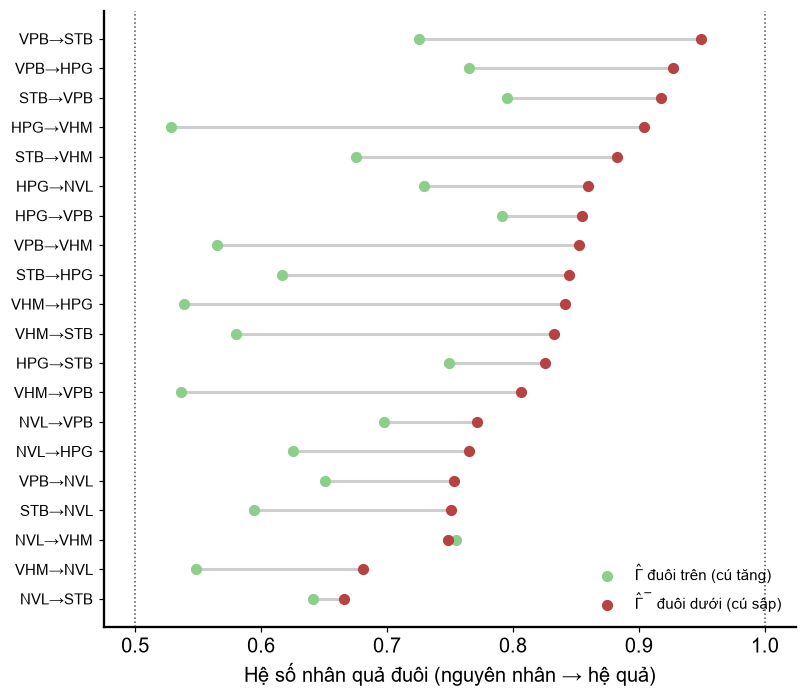

Trung bình: Γ̂ trên = 0.655, Γ̂⁻ dưới = 0.822; số cặp Γ̂⁻ > Γ̂: 19/20


,tren,duoi
cap,,
VPB→STB,0.725,0.949
VPB→HPG,0.765,0.927
STB→VPB,0.795,0.918
HPG→VHM,0.529,0.904
STB→VHM,0.675,0.883
HPG→NVL,0.729,0.859


In [7]:
Gu = CT.tail_coef_matrix(z, k=K, kind="gamma_upper"); Gl = CT.tail_coef_matrix(z, k=K, kind="gamma_lower")
pairs = [(a, b) for a in SYMBOLS for b in SYMBOLS if a != b]
dd = pd.DataFrame({"cap": [f"{a}→{b}" for a, b in pairs], "tren": [Gu.loc[a, b] for a, b in pairs],
                   "duoi": [Gl.loc[a, b] for a, b in pairs]}).sort_values("duoi")
fig, ax = plt.subplots(figsize=(7.5, 6.5))
y = np.arange(len(dd))
ax.hlines(y, dd.tren, dd.duoi, color=PAL["neutral"], lw=2)
ax.scatter(dd.tren, y, color=PAL["green_3"], s=40, zorder=3, label=r"$\hat\Gamma$ đuôi trên (cú tăng)")
ax.scatter(dd.duoi, y, color=PAL["red_strong"], s=40, zorder=3, label=r"$\hat\Gamma^{-}$ đuôi dưới (cú sập)")
ax.axvline(0.5, color=PAL["gray_dark"], ls=":", lw=1); ax.axvline(1, color=PAL["gray_dark"], ls=":", lw=1)
ax.set_yticks(y, dd.cap, fontsize=10); ax.set_xlabel("Hệ số nhân quả đuôi (nguyên nhân → hệ quả)")
ax.legend(fontsize=10, loc="lower right")
U.finalize_figure(fig, "finding_6_crash_vs_rally", folder=FOLDER); plt.show()
print(f"Trung bình: Γ̂ trên = {dd.tren.mean():.3f}, Γ̂⁻ dưới = {dd.duoi.mean():.3f}; "
      f"số cặp Γ̂⁻ > Γ̂: {(dd.duoi > dd.tren).sum()}/{len(dd)}")
dd.set_index("cap").sort_values("duoi", ascending=False).head(6)

### Phân tích

- Ở 19/20 cặp, hệ số đuôi dưới lớn hơn đuôi trên; trung bình 0,82 so với 0,66. Một số cặp sát 1 ở đuôi dưới: VPB→STB 0,95,
  VPB→HPG 0,93, STB→VPB 0,92 — khi một ngân hàng sập, mã còn lại gần như chắc chắn cũng ở vùng thấp nhất.
- Vì cả hai chiều trong nhóm ngân hàng–thép đều cao, theo mục 4.3 của bài báo đây là dấu hiệu của một **nguồn sốc chung đuôi dày hơn**
  (ví dụ cú bán tháo toàn thị trường), không phải chuỗi lây lan trực tiếp.
- Nhất quán với EDA phát hiện 7 (phụ thuộc đuôi dưới vượt mức Gaussian). Hệ quả: mô hình rủi ro (VaR/ES danh mục) cần đối xử
  đuôi dưới riêng, không thể dùng chung một hệ số phụ thuộc cho cả hai đuôi.

## Phát hiện 7 — Các baseline đồng thuận với EASE; Rank PC không định hướng được

**Tính gì:** thứ tự nhân quả của EASE, Pairwise LiNGAM, ICA-LiNGAM (thứ tự phổ biến nhất qua 10 seed) trên cùng $z$
(bảng `02_baseline_orders.csv`) và độ đồng thuận cặp:
$$\mathrm{agr}(\pi,\pi') = \binom{p}{2}^{-1}\sum_{i<j}\mathbb 1\{\text{$\pi$ và $\pi'$ xếp $i, j$ cùng chiều}\}.$$
Mức nền: hai thứ tự ngẫu nhiên có $\mathrm{agr}$ trung bình 0,5, phân vị 95% = 0,8. Rank PC trả CPDAG nên chỉ báo số cạnh định hướng được.

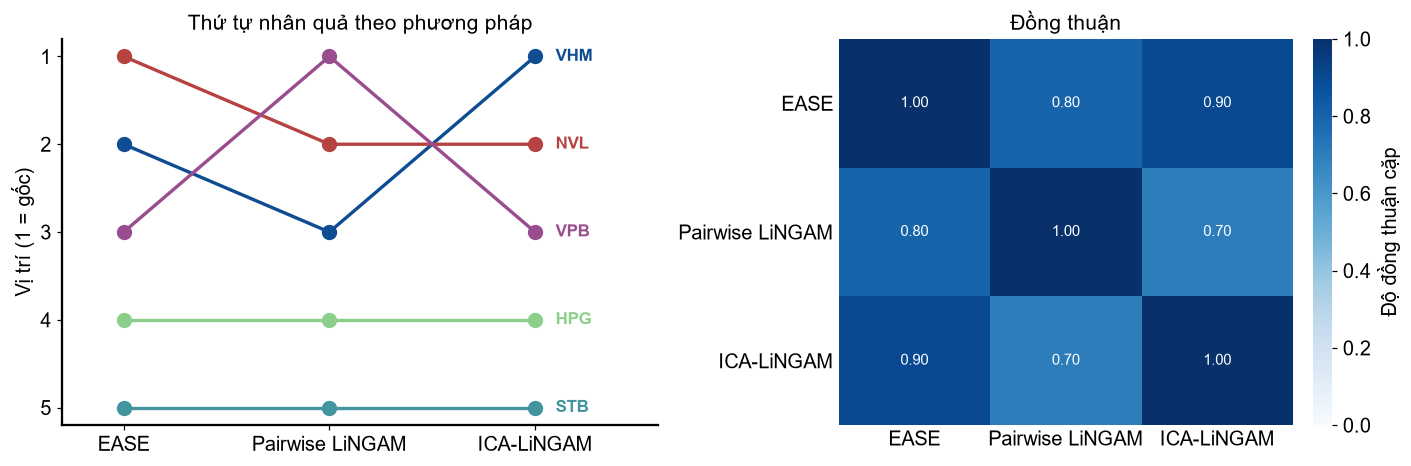

Rank PC: 0 cạnh có hướng, 10 cạnh vô hướng (tối đa 10)


,1,2,3,4,5
EASE,NVL,VHM,VPB,HPG,STB
Pairwise LiNGAM,VPB,NVL,VHM,HPG,STB
ICA-LiNGAM,VHM,NVL,VPB,HPG,STB


In [8]:
orders = read("02_baseline_orders", index_col=0)
agree = read("02_baseline_agreement", index_col=0)
names = list(orders.index)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.2, 1]})
for s in SYMBOLS:
    ranks = [list(orders.loc[m]).index(s) + 1 for m in names]
    axes[0].plot(range(len(names)), ranks, "o-", color=COL[s], lw=2.2, ms=9)
    axes[0].text(len(names) - 1 + 0.1, ranks[-1], s, color=COL[s], va="center", fontsize=11, fontweight="bold")
axes[0].set_xticks(range(len(names)), names); axes[0].set_yticks(range(1, 6)); axes[0].invert_yaxis()
axes[0].set_xlim(-0.3, len(names) - 0.4); axes[0].set_ylabel("Vị trí (1 = gốc)")
axes[0].set_title("Thứ tự nhân quả theo phương pháp")
U.make_heatmap(axes[1], agree, cmap="Blues", vmin=0, vmax=1, cbar_label="Độ đồng thuận cặp", title="Đồng thuận")
U.finalize_figure(fig, "finding_7_baselines", folder=FOLDER); plt.show()
pc = CB.run_rank_pc(z.to_numpy())["adj"]
n_dir = int(((pc == 1) & (pc.T == 0)).sum()); n_und = int(((pc == 1) & (pc.T == 1)).sum() // 2)
print(f"Rank PC: {n_dir} cạnh có hướng, {n_und} cạnh vô hướng (tối đa 10)")
orders

### Phân tích

- EASE đồng thuận 0,9 với ICA-LiNGAM và 0,8 với Pairwise LiNGAM — ở mức phân vị 95% của thứ tự ngẫu nhiên trở lên. Cả ba đặt **HPG thứ 4,
  STB cuối**, NVL và VHM trong 3 vị trí đầu.
- EASE chỉ dùng 42 phiên cực trị mỗi mã, LiNGAM dùng toàn bộ 2.120 phiên — sự đồng thuận cho thấy cấu trúc "bất động sản trước,
  ngân hàng/thép sau" có mặt **cả ở phần thân lẫn phần đuôi** phân phối.
- Rank PC cho đồ thị đầy đủ vô hướng: mọi cặp vẫn phụ thuộc sau khi điều kiện trên 3 mã còn lại — dấu hiệu nhân tố chung không quan sát được,
  khớp phát hiện 4.

## Hướng tiếp theo

1. Thêm **VN-Index** (hoặc nhân tố thị trường) như biến quan sát: kiểm tra nó có là gốc với $\Gamma \approx 1$ tới các mã — đúng vai trò
   EURCHF trong ví dụ của bài báo.
2. Chạy EASE trên **phần dư sau khi loại nhân tố thị trường** để tách nhân quả giữa các mã khỏi nguồn sốc chung.
3. Phân tích EASE theo **cửa sổ trượt** (bài báo, Phụ lục F) để xem thứ tự có đổi giữa các giai đoạn (2020, 2022–2023).